# 演習7：H₄の実機信号は回路を短くすると戻るか

06と同じ **R=2.0 Å、準備M6、MPO由来の発展M16、系8＋補助1 qubit** を使い、
発展の反復数 **L=1・2・4** で干渉信号を比較します。06を先に実行する必要はありません。

目的は「短い回路では山が見え、長くすると信号が消えるか」の検証です。
GaussianフィットやBayes更新、ギャップの数値推定は行いません。
接続と送信は初期設定では無効です。上から通し実行すると、シミュレーションだけを検証できます。

論文の[Fig. 2](https://doi.org/10.1073/pnas.2425026122)はHubbard模型におけるMPO圧縮とTrotter回路の比較です。
この演習は **既にMPOで圧縮した同じ部品のL依存性** を調べる追加実験で、Fig. 2そのものの再現ではありません。


In [1]:
# 初回は必要に応じてコメントを外し、インストール後にカーネルを再起動してください。
# %pip install "numpy>=1.26,<3" "scipy>=1.12,<2" "matplotlib>=3.8,<4" "qiskit==2.4.1" "pylatexenc>=2.10,<3"
# 実機接続時は後の接続セルが qiskit-ibm-runtime>=0.43,<0.44 を導入します。


## 1．固定データの読み込み

05・06と同じ固定コミット・SHA-256検証を使います。下の初期化セルの
`H4_CACHE_DIR` で保存先、`H4_OFFLINE` で取得禁止を指定できます。
リポジトリ内のデータを優先し、不足分だけを取得します。
ColabでDriveに保存する場合は、先に `drive.mount('/content/drive')` を実行してください。
ここではMPS/MPOの最適化を再実行せず、生成済みの量子回路を読み込みます。


In [1]:
H4_DATA_COMMIT = "4ab6ef3d06f4256b5c818feb8c3fa2af4381dd43"
# 保存先を指定する場合の例（Google Driveは先にmountする）:
# H4_CACHE_DIR = '/content/drive/MyDrive/FTQC_HandsOn/h4_pec_v1'
H4_CACHE_DIR = (
    None  # None: H4_DATA_DIR環境変数 → 取得済みリポジトリ → ユーザーキャッシュ
)
H4_OFFLINE = False  # True: ダウンロードせず、既存ファイルのみを使用

import os, json, hashlib, base64, tempfile
from pathlib import Path
from urllib.request import urlopen

SNAPSHOT_DIGEST = "6910f1f0aa7d0f2e43499683ba3a50f83db7aee09f3c64b07c91a6815ebdd4b3"
ASSET_DIGEST = SNAPSHOT_DIGEST
_H4_URL = f"https://raw.githubusercontent.com/QS-laboratory/IBM_handson/{H4_DATA_COMMIT}/hands_on/exercises/"
_H4_RUNTIME = {
    "h4_measurement.py": "d4dea4170f5e925599dcbbbc3b2c0ee7f2da1e25d7844ec024759e415c3a35f4",
    "h4_snapshot.py": "163691a0c005c844e0e449411c59eb5192218402df999c77056cbd7b223be997",
}


def snapshot_root():
    explicit = os.environ.get("H4_DATA_DIR") or H4_CACHE_DIR
    root = Path(explicit).expanduser().resolve() if explicit else None
    if root is None:
        for parent in [Path.cwd(), *Path.cwd().parents]:
            for candidate in [
                parent / "data/h4_pec_v1",
                parent / "hands_on/exercises/data/h4_pec_v1",
            ]:
                if (candidate / "manifest.json").is_file():
                    root = candidate
                    break
            if root is not None:
                break
    if root is None:
        root = Path.home() / ".cache/ftqc_handson/h4_pec_v1"
    if (
        str(root).startswith("/content/drive/MyDrive/")
        and not Path("/content/drive/MyDrive").is_dir()
    ):
        raise FileNotFoundError(
            '先に drive.mount("/content/drive") でGoogle Driveを接続してください'
        )
    manifest = root / "manifest.json"
    if (
        manifest.is_file()
        and hashlib.sha256(manifest.read_bytes()).hexdigest() != SNAPSHOT_DIGEST
    ):
        raise ValueError("Snapshot manifest differs from the pinned h4-pec-v1 manifest")
    return root


def _h4_fetch(path, url, digest):
    path = Path(path)
    if path.is_file():
        raw = path.read_bytes()
    else:
        if H4_OFFLINE:
            raise FileNotFoundError(
                f"Offline: missing {path}; pre-download the required data"
            )
        try:
            with urlopen(url, timeout=60) as response:
                raw = response.read()
        except Exception as exc:
            raise RuntimeError(
                f"H4データを取得できません: {path.name}. 接続またはH4_DATA_DIR/H4_CACHE_DIRを確認してください。"
            ) from exc
        if hashlib.sha256(raw).hexdigest() != digest:
            raise ValueError(f"Snapshot checksum mismatch: {path.name}")
        path.parent.mkdir(parents=True, exist_ok=True)
        tmp = None
        try:
            with tempfile.NamedTemporaryFile(dir=path.parent, delete=False) as stream:
                tmp = Path(stream.name)
                stream.write(raw)
            os.replace(tmp, path)
        finally:
            if tmp is not None:
                tmp.unlink(missing_ok=True)
    if hashlib.sha256(raw).hexdigest() != digest:
        raise ValueError(f"Snapshot checksum mismatch: {path.name}")
    return raw


def _h4_data(relative):
    digest = (
        SNAPSHOT_DIGEST
        if relative == "manifest.json"
        else SNAPSHOT_INDEX["files"][relative]
    )
    return _h4_fetch(
        snapshot_root() / relative, _H4_URL + "data/h4_pec_v1/" + relative, digest
    )


SNAPSHOT_INDEX = json.loads(_h4_data("manifest.json"))


class _H4Assets:
    """Read only the requested asset; no notebook-embedded binary strings."""

    def __init__(self, row):
        self.row = row

    def __getitem__(self, key):
        raw = _h4_data(self.row["id"] + "/" + self.row["assets"][key])
        return base64.b64encode(raw).decode()


def _h4_geometry(geometry):
    row = next((r for r in SNAPSHOT_INDEX["geometries"] if r["id"] == geometry), None)
    if row is None:
        raise ValueError("Unknown GEOMETRY; choose an ID from list_geometries()")
    cat = json.loads(_h4_data(geometry + "/catalog.json"))
    for name in ["preparation", "evolution"]:
        cat[name] = {int(k) if k != "exact" else k: v for k, v in cat[name].items()}
    return _H4Assets(row), cat, json.loads(_h4_data(geometry + "/provenance.json"))


ASSETS, CIRCUIT_CATALOG, PROVENANCE = _h4_geometry("R_2p00000000")
exec(
    compile(_h4_data("exact_preparation.py"), "h4_pec_v1/exact_preparation.py", "exec"),
    globals(),
)
_h4_cache_root = snapshot_root
for _name, _digest in _H4_RUNTIME.items():
    _local = snapshot_root().parent.parent / "tools" / _name
    _path = (
        _local
        if _local.is_file()
        else snapshot_root().parent
        / (snapshot_root().name + "_runtime")
        / H4_DATA_COMMIT
        / _name
    )
    exec(
        compile(_h4_fetch(_path, _H4_URL + "tools/" + _name, _digest), _name, "exec"),
        globals(),
    )
# The pinned runtime supplies measurement/inference helpers. Replace its eager
# snapshot reader with the verified, per-file cache above.
snapshot_geometry = _h4_geometry
snapshot_root = _h4_cache_root


def download_h4_data(
    geometries="all", prep_m=(4, 6, 8, "exact"), evolution_m=(8, 16, 32, "exact")
):
    """Optional prefetch for offline use. This never changes active circuits."""
    ids = (
        [r["id"] for r in SNAPSHOT_INDEX["geometries"]]
        if geometries == "all"
        else list(geometries)
    )
    count = 0
    for geometry in ids:
        row = next(
            (r for r in SNAPSHOT_INDEX["geometries"] if r["id"] == geometry), None
        )
        if row is None:
            raise ValueError("Unknown GEOMETRY")
        assets, cat, _ = _h4_geometry(geometry)
        keys = {"model"}
        for m in prep_m:
            keys.update(cat["preparation"][m]["keys"].values())
        for m in evolution_m:
            keys.add(cat["evolution"][m]["key"])
        for key in sorted(keys):
            assets[key]
            count += 1
    print(f"Cached {len(ids)} geometries / {count} assets in {snapshot_root()}")


print(
    "H4 data cache:",
    snapshot_root(),
    "— missing files are downloaded on demand; existing files are verified and reused.",
)


R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L
H4 data cache: /Users/payashi/Documents/research/IBM_handson/hands_on/exercises/data/h4_pec_v1 — missing files are downloaded on demand; existing files are verified and reused.


## 2．比較条件：同じ位相範囲を走査する

補正角は $\beta=\varepsilon L\Delta t$ です。06のエネルギー範囲 $[-4,4]$ Haをそのまま使うと、
Lを短くするだけで**理想信号も平坦**になります。そこで各Lで同じ位相角
$[-\pi,\pi)$ を12等分し、必ず干渉の一周期を観測します。エネルギー範囲はLごとに異なります。

| 量         | 設定                                                |
| ---------- | --------------------------------------------------- |
| L          | 1、2、4（t=0.1、0.2、0.4 a.u.）                     |
| 準備／発展 | M6／M16、06と同じ保存回路                           |
| 位相       | 12点、端点の重複なし                                |
| 繰り返し   | 各位相2回、各回SHOTS shots                          |
| 実行       | 72回路を順序を混ぜて1ジョブへ送信                   |
| 配置       | 全Lで同じ初期論理→物理qubit配置、配置後の回路を確認 |

既定の総要求量は **72×1024=73,728 shots** です。`REPEATS` は独立な較正ではありません。
回路順のランダム化はドリフトとの相関を減らしますが、サービス側の実行順序や定常性を保証しません。


In [2]:
SHOTS = 1024
REPEATS = 2
ORDER_SEED = 42
RUN_LABEL = "depth_scan_01"  # 同条件の新規測定は別ラベルにする
OUTPUT_DIR = Path("outputs/exercise7")
L_VALUES = (1, 2, 4)
PHASES = np.linspace(-np.pi, np.pi, 12, endpoint=False)

for name, value in [("SHOTS", SHOTS), ("REPEATS", REPEATS)]:
    if not isinstance(value, int) or isinstance(value, bool) or value < 1:
        raise ValueError(f"{name}は正の整数を指定してください")
if not isinstance(RUN_LABEL, str) or not RUN_LABEL.strip():
    raise ValueError("RUN_LABELは空でない文字列を指定してください")
select_geometry("R_2p00000000")
select_circuits(6, 16)


def current_configuration():
    return dict(
        geometry=SELECTED_GEOMETRY,
        circuit_digest=CIRCUIT_DIGEST,
        prep_m=SELECTED_PREP_M,
        evolution_m=SELECTED_EVOLUTION_M,
        dt=DT,
        L_values=list(L_VALUES),
        phases=PHASES.tolist(),
        shots=SHOTS,
        repeats=REPEATS,
        order_seed=ORDER_SEED,
        run_label=RUN_LABEL,
    )


for length in L_VALUES:
    gaps = PHASES / (length * DT)
    print(
        f"L={length}, t={length * DT:.1f}: trial gaps {gaps[0]:.3f} .. {gaps[-1]:.3f} Ha; "
        f"serial CX={SERIAL_CX['preparation'] + length * SERIAL_CX['evolution']}"
    )
print("Circuits:", len(L_VALUES) * len(PHASES) * REPEATS)
print("Total requested shots:", len(L_VALUES) * len(PHASES) * REPEATS * SHOTS)


R_2p00000000: PREP_M=6 (S0/T), EVOLUTION_M=16; serial CX = 516 + 216 L
L=1, t=0.1: trial gaps -31.416 .. 26.180 Ha; serial CX=732
L=2, t=0.2: trial gaps -15.708 .. 13.090 Ha; serial CX=948
L=4, t=0.4: trial gaps -7.854 .. 6.545 Ha; serial CX=1380
Circuits: 72
Total requested shots: 73728


## 3．干渉信号を確認するための集計

全0頻度に **点ごとの95% Wilson区間** を付けます。全0が0回でも区間幅は0にはなりません。
$C+a\cos\beta+b\sin\beta$ の線形射影から振幅 $\sqrt{a^2+b^2}$ を求めますが、
ノイズだけでも正の振幅になるため、それだけで「山を検出」とはしません。射影は記述統計です。

帰無仮説は「このLでは全位相で全0確率が一定」です。全0総数を固定し、各位相の実shots数に応じた
**多変量超幾何分布**から帰無データを生成します。第一調和成分のスコアを比較し、Monte Carlo p値を求めます。
3つのLにはBonferroni補正を適用します。これは定常で独立な二項測定を仮定した位相依存性の検査であり、
ギャップ推定やノイズ機構の証明ではありません。検出なしは「信号ゼロの証明」ではありません。

図の左は絶対確率0〜1、右は実測範囲の拡大です。最大値で正規化しません。
$1/512$ は一様な9ビット測定の参考値であり、検定で仮定する確率ではありません。


In [3]:
def wilson_interval(k, n, z=1.959963984540054):
    k, n = np.asarray(k, float), np.asarray(n, float)
    if np.any(n <= 0) or np.any(k < 0) or np.any(k > n):
        raise ValueError("0 <= counts <= positive shots が必要です")
    p = k / n
    denominator = 1 + z * z / n
    center = (p + z * z / (2 * n)) / denominator
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / denominator
    return np.maximum(0, center - half), np.minimum(1, center + half)


def summarize_scan(beta, k, n, seed=42, simulations=4999):
    beta = np.asarray(beta, float)
    k, n = np.asarray(k), np.asarray(n)
    if (
        beta.ndim != 1
        or len(beta) < 3
        or k.shape != beta.shape
        or n.shape != beta.shape
        or not np.all(np.isfinite(beta))
        or not np.issubdtype(k.dtype, np.integer)
        or not np.issubdtype(n.dtype, np.integer)
        or np.any(n <= 0)
        or np.any(k < 0)
        or np.any(k > n)
    ):
        raise ValueError("位相と整数counts/shotsの配列を確認してください")
    basis = np.column_stack([np.cos(beta), np.sin(beta)])
    design = np.column_stack([np.ones(len(beta)), basis])
    if np.linalg.matrix_rank(design) != 3:
        raise ValueError("位相点が干渉曲線を決定できません")
    coefficients = np.linalg.lstsq(
        design * np.sqrt(n[:, None]), k / np.sqrt(n), rcond=None
    )[0]
    low, high = wilson_interval(k, n)
    total, trials = int(k.sum()), int(n.sum())
    pooled = total / trials
    centered = basis - np.average(basis, axis=0, weights=n)
    metric = np.linalg.pinv(centered.T @ (n[:, None] * centered))
    score = (k - n * pooled) @ centered
    statistic = float(score @ metric @ score)
    if total == 0 or total == trials:
        pvalue = 1.0
    else:
        null_k = np.random.default_rng(seed).multivariate_hypergeometric(
            n, total, size=simulations
        )
        null_scores = (null_k - n * pooled) @ centered
        null_stats = np.einsum("bi,ij,bj->b", null_scores, metric, null_scores)
        pvalue = float(
            (1 + np.count_nonzero(null_stats >= statistic - 1e-14)) / (simulations + 1)
        )
    return dict(
        beta=beta.tolist(),
        counts_all_zero=k.tolist(),
        actual_shots=n.tolist(),
        observed=(k / n).tolist(),
        lower_95=low.tolist(),
        upper_95=high.tolist(),
        coefficients=coefficients.tolist(),
        amplitude=float(np.hypot(*coefficients[1:])),
        constant_probability=pooled,
        statistic=statistic,
        p_value=pvalue,
        monte_carlo_samples=simulations,
    )


def plot_scans(scans, title):
    dense = np.linspace(-np.pi, np.pi, 401)
    fig, axes = plt.subplots(
        len(scans), 2, figsize=(11, 2.8 * len(scans)), squeeze=False
    )
    for row, scan in enumerate(scans):
        length = scan["L"]
        beta = np.asarray(scan["beta"])
        y = np.asarray(scan["observed"])
        low, high = np.asarray(scan["lower_95"]), np.asarray(scan["upper_95"])
        ideal = probability("both", length, dense / (length * DT))
        coeff = scan["coefficients"]
        projection = coeff[0] + coeff[1] * np.cos(dense) + coeff[2] * np.sin(dense)
        for column, ax in enumerate(axes[row]):
            ax.errorbar(
                beta,
                y,
                yerr=np.maximum(0, np.array([y - low, high - y])),
                fmt="o",
                ms=3,
                capsize=2,
                label="All-zero frequency / pointwise 95% CI",
            )
            ax.axhline(1 / 512, color="gray", ls=":", label="Uniform 9-bit reference")
            if column == 0:
                ax.plot(dense, ideal, "--", label="Noiseless M6/M16")
                ax.set_ylim(-0.02, 1.02)
            else:
                ax.plot(dense, projection, label="Harmonic projection (descriptive)")
                ax.set_ylim(
                    min(0.0, float(projection.min()) * 1.1),
                    max(1 / 512, float(high.max()), float(projection.max())) * 1.15,
                )
            ax.set(
                xlabel="Correction phase beta / rad",
                ylabel="P(all zero)",
                title=f"L={length}, t={length * DT:.1f}"
                + (" (zoom)" if column else ""),
            )
            ax.legend(fontsize=6)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()
    plt.close(fig)


def print_scan_summary(scans):
    print(
        "L | all zero / actual shots | harmonic amplitude | p (3-L adjusted) | phase dependence"
    )
    for scan in scans:
        scan["p_adjusted"] = min(1.0, len(scans) * scan["p_value"])
        scan["phase_dependence_detected"] = scan["p_adjusted"] < 0.05
        flag = "detected" if scan["phase_dependence_detected"] else "unresolved"
        print(
            f"{scan['L']} | {sum(scan['counts_all_zero'])}/{sum(scan['actual_shots'])} | "
            f"{scan['amplitude']:.6g} | {scan['p_adjusted']:.4g} | {flag}"
        )


L | all zero / actual shots | harmonic amplitude | p (3-L adjusted) | phase dependence
1 | 12376/24576 | 0.496447 | 0.0006 | detected
2 | 12286/24576 | 0.497183 | 0.0006 | detected
4 | 12257/24576 | 0.499183 | 0.0006 | detected


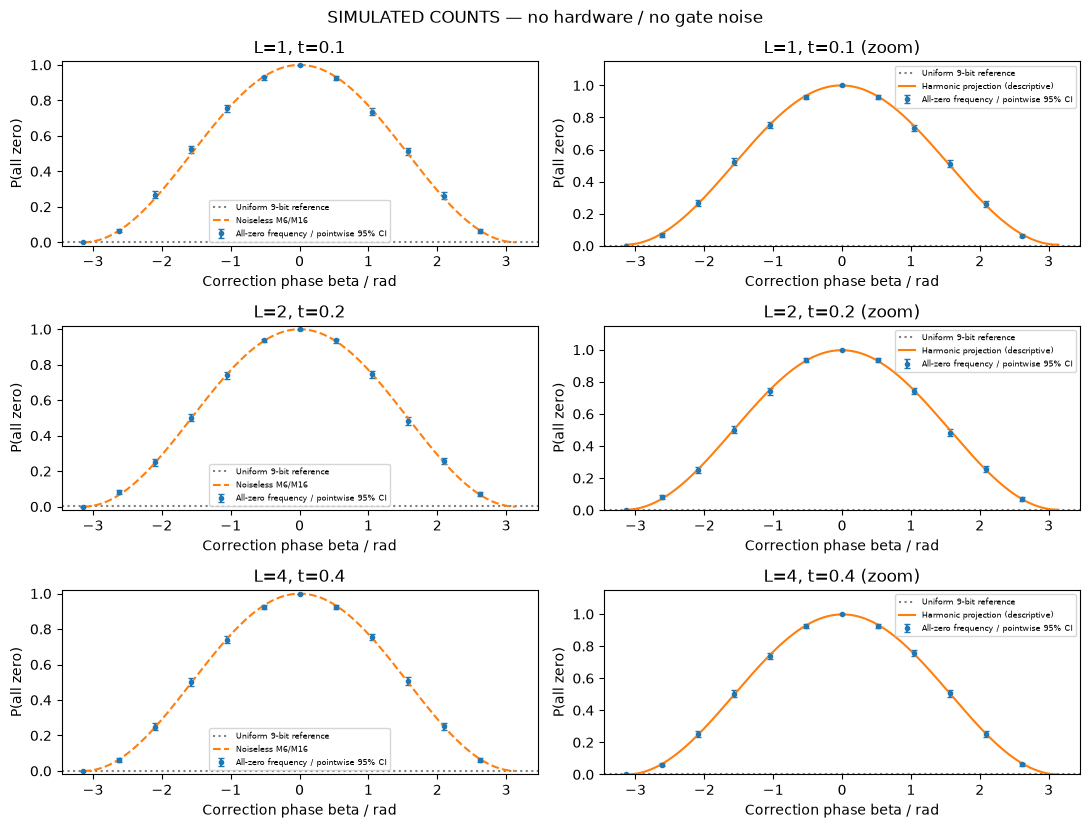

Saved: outputs/exercise7/simulation_reference.json


In [4]:
# 独立したシミュレーション対照。実機結果ではありません。
rng = np.random.default_rng(42)
simulation_scans = []
for length in L_VALUES:
    gaps = PHASES / (length * DT)
    p = probability("both", length, gaps)
    for beta, gap, expected in zip(PHASES, gaps, p):
        actual = (
            abs(
                Statevector.from_instruction(
                    experiment_circuit(length, float(gap))
                ).data[0]
            )
            ** 2
        )
        np.testing.assert_allclose(actual, expected, atol=1e-10, rtol=0)
    n = np.full(len(PHASES), SHOTS * REPEATS, dtype=int)
    scan = summarize_scan(PHASES, rng.binomial(n, p), n, seed=42 + length)
    simulation_scans.append(dict(L=length, **scan))
print_scan_summary(simulation_scans)
plot_scans(simulation_scans, "SIMULATED COUNTS — no hardware / no gate noise")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
simulation_path = OUTPUT_DIR / "simulation_reference.json"
simulation_path.write_text(
    json.dumps(
        dict(
            source="simulated_counts",
            configuration=current_configuration(),
            scans=simulation_scans,
        ),
        indent=2,
    )
)
print("Saved:", simulation_path)


## 4．IBM接続（実機を使う場合のみ）

次セルを `USE_IBM=True` に変更し、CRN・APIキー・backendを入力してください。
APIキーは非表示入力します。[接続ガイド](../../docs/02_colab_connection.md)も参照してください。
接続だけでは送信しません。06の接続状態や保存ジョブは引き継ぎません。


In [5]:
USE_IBM = True  # 実機を使う方のみ True に変更
IBM_SERVICE = None
IBM_INSTANCE = ""
IBM_BACKEND_NAME = ""

if USE_IBM:
    import subprocess
    import sys
    from getpass import getpass

    subprocess.check_call(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "qiskit==2.4.1",
            "qiskit-ibm-runtime>=0.43,<0.44",
        ]
    )
    from qiskit_ibm_runtime import QiskitRuntimeService

    IBM_INSTANCE = input("今回使うインスタンスのCRN：").strip()
    if not IBM_INSTANCE.startswith("crn:"):
        raise ValueError("インスタンスのCRN（crn:で始まる文字列）を入力してください")
    _api_key = getpass("本人のAPIキー（非表示）：").strip()
    try:
        IBM_SERVICE = QiskitRuntimeService(
            channel="ibm_quantum_platform",
            token=_api_key,
            instance=IBM_INSTANCE,
        )
    finally:
        del _api_key

    _backend_names = sorted(b.name for b in IBM_SERVICE.backends())
    print("利用可能なバックエンド：", ", ".join(_backend_names))
    if not _backend_names:
        raise RuntimeError("利用可能な実機がありません。主催者へお知らせください")
    IBM_BACKEND_NAME = input("一覧から今回使うバックエンド名を入力：").strip()
    if IBM_BACKEND_NAME not in _backend_names:
        raise ValueError(
            "一覧にあるバックエンド名を入力し、このセルを再実行してください"
        )
    print("接続確認完了：", IBM_BACKEND_NAME, "（ジョブは送信していません）")
else:
    print("IBM接続準備をスキップしました。シミュレータで演習できます。")



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
qiskit_runtime_service._discover_account:WARNING:2026-11-09 14:44:30,227: Loading account with the given token. A saved account will not be used.


利用可能なバックエンド： ibm_kawasaki
接続確認完了： ibm_kawasaki （ジョブは送信していません）


## 5．同じ初期配置で3種類をプレビューする

最初にL=1の配置を選び、その**初期配置をL=2・4にも指定**します。L間のrouting・最終配置は異なり得ます。
パラメータ付きの各L回路を一度だけ配置し、その回路に12種類の位相を代入します。
したがって、同じLで位相ごとにゲート数や配置が変わることはありません。

全Lの深さ・2 qubitゲート数・初期／最終配置・routingを含む使用qubitを表示します。
この段階で実際に送る回路を準備し、送信時に再トランスパイルしません。
FireOpal等の追加の誤り抑制は有効にしていません。設定変更後はプレビューからやり直してください。


In [6]:
from qiskit.circuit import Parameter
import qiskit
from datetime import datetime, timezone


def phase_template(length):
    beta = Parameter("beta")
    circuit = QuantumCircuit(9)
    circuit.compose(A_APPROX, inplace=True)
    for _ in range(length):
        circuit.compose(EVOLUTION_APPROX, range(8), inplace=True)
    circuit.p(beta, 8)
    circuit.compose(A_APPROX.inverse(), inplace=True)
    circuit.measure_all()
    return circuit


def circuit_signature(circuit):
    # Parameter names and instruction coordinates avoid random Parameter UUIDs.
    instructions = [
        dict(
            name=item.operation.name,
            params=[str(p) for p in item.operation.params],
            qubits=[circuit.find_bit(q).index for q in item.qubits],
            clbits=[circuit.find_bit(c).index for c in item.clbits],
        )
        for item in circuit.data
    ]
    payload = dict(
        qubits=circuit.num_qubits,
        clbits=circuit.num_clbits,
        global_phase=str(circuit.global_phase),
        instructions=instructions,
    )
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()


def make_preview(backend, instance):
    templates, reports = {}, []
    common_layout = None
    for length in L_VALUES:
        isa = transpile(
            phase_template(length),
            backend=backend,
            initial_layout=common_layout,
            optimization_level=1,
            seed_transpiler=7,
        )
        initial = isa.layout.initial_index_layout(filter_ancillas=True)
        if common_layout is None:
            common_layout = initial
        if initial != common_layout or len(isa.parameters) != 1:
            raise RuntimeError("初期配置または位相パラメータが変わりました")
        templates[length] = isa
        report = dict(
            L=length,
            depth=isa.depth(),
            two_qubit_gates=sum(item.operation.num_qubits == 2 for item in isa.data),
            operations=dict(isa.count_ops()),
            initial_layout=initial,
            final_layout=isa.layout.final_index_layout(filter_ancillas=True),
            active_physical_qubits=sorted(
                {
                    isa.find_bit(q).index
                    for item in isa.data
                    if item.operation.name != "barrier"
                    for q in item.qubits
                }
            ),
            signature=circuit_signature(isa),
        )
        reports.append(report)
        print(json.dumps(report, indent=2))
    # Randomize L and phase within each repeat; all repeats share one job.
    rng = np.random.default_rng(ORDER_SEED)
    schedule = []
    for repeat in range(REPEATS):
        block = [
            dict(repeat=repeat, L=length, phase_index=j, beta=float(beta))
            for length in L_VALUES
            for j, beta in enumerate(PHASES)
        ]
        schedule.extend(block[int(j)] for j in rng.permutation(len(block)))
    circuits = []
    for row in schedule:
        template = templates[row["L"]]
        circuits.append(
            template.assign_parameters({next(iter(template.parameters)): row["beta"]})
        )
    spec = dict(
        configuration=current_configuration(),
        backend=backend.name,
        instance_sha256=hashlib.sha256(instance.encode()).hexdigest(),
        qiskit_version=qiskit.__version__,
        optimization_level=1,
        seed_transpiler=7,
        reports=reports,
        schedule=schedule,
    )
    key = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()
    print(
        f"READY: {len(circuits)} circuits × {SHOTS} shots = {len(circuits) * SHOTS} requested shots"
    )
    return dict(specification=spec, key=key, circuits=circuits)


backend = None
preview = None
if IBM_SERVICE is not None:
    backend = IBM_SERVICE.backend(IBM_BACKEND_NAME)
    preview = make_preview(backend, IBM_INSTANCE)
else:
    print("IBM接続なし：実機プレビューをスキップしました。")


{
  "L": 1,
  "depth": 2347,
  "two_qubit_gates": 1230,
  "operations": {
    "rz": 3196,
    "sx": 2904,
    "cz": 1230,
    "x": 45,
    "measure": 9,
    "barrier": 1
  },
  "initial_layout": [
    155,
    154,
    153,
    152,
    151,
    150,
    138,
    149,
    139
  ],
  "final_layout": [
    139,
    155,
    153,
    152,
    151,
    150,
    138,
    149,
    154
  ],
  "active_physical_qubits": [
    138,
    139,
    149,
    150,
    151,
    152,
    153,
    154,
    155
  ],
  "signature": "655116b800bbc9cf721c7276e1447b77ed25fc2311f898048cbffec72cd7385b"
}
{
  "L": 2,
  "depth": 2619,
  "two_qubit_gates": 1398,
  "operations": {
    "rz": 4036,
    "sx": 3464,
    "cz": 1398,
    "x": 45,
    "measure": 9,
    "barrier": 1
  },
  "initial_layout": [
    155,
    154,
    153,
    152,
    151,
    150,
    138,
    149,
    139
  ],
  "final_layout": [
    139,
    155,
    153,
    152,
    151,
    150,
    138,
    149,
    154
  ],
  "active_physical_qubits":

## 6．実機測定：プレビューした回路を1ジョブで送信

費用を確認してから `RUN_HARDWARE=True` に変更してください。新規送信前に、送信マーカーと
プレビュー済みISA回路（QPY）を保存します。ジョブIDを取得したら直ちに保存します。
取得した**全ビットcountsを解析前に保存**するので、解析で失敗しても再送信する必要はありません。

同じ設定・配置済み回路・backend・instance・`RUN_LABEL` の保存結果／ジョブを再利用します。
新しく測定したいときは `RUN_LABEL` を変えて設定とプレビューを再実行してください。
送信中断でIDのないマーカーが残った場合は、IBMのジョブ一覧を確認して復旧します。自動再送信しません。

記録は `outputs/exercise7/ibm_jobs/` 以下です。Colab切断前にフォルダをDrive等へ保存してください。
CRNそのものやAPIキーは記録へ含めません。


In [7]:
def atomic_json(path, record):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with tempfile.NamedTemporaryFile(mode="w", dir=path.parent, delete=False) as stream:
        temp = Path(stream.name)
        json.dump(record, stream, indent=2)
    try:
        os.replace(temp, path)
    finally:
        temp.unlink(missing_ok=True)


def validate_counts(raw, count):
    if len(raw) != count:
        raise ValueError("取得したPUB数と送信回路数が一致しません")
    for counts in raw:
        if not isinstance(counts, dict) or not counts:
            raise ValueError("空のcountsです")
        if (
            any(
                not isinstance(s, str)
                or len(s) != 9
                or set(s) - set("01")
                or not isinstance(v, int)
                or isinstance(v, bool)
                or v < 0
                for s, v in counts.items()
            )
            or sum(counts.values()) <= 0
        ):
            raise ValueError(
                "countsの9ビット文字列・整数回数・実shots数を確認してください"
            )


def acquire_scan(preview, service, backend, instance, directory):
    if preview is None or service is None or backend is None:
        raise RuntimeError("先にIBM接続とプレビューを実行してください")
    spec = preview["specification"]
    if (
        spec["configuration"] != current_configuration()
        or spec["backend"] != backend.name
        or spec["instance_sha256"] != hashlib.sha256(instance.encode()).hexdigest()
    ):
        raise RuntimeError(
            "設定または接続が変わりました。プレビューを再実行してください"
        )
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / (preview["key"] + ".json")
    if path.exists():
        record = json.loads(path.read_text())
        if record["specification"] != spec:
            raise ValueError("保存済みの測定条件が一致しません")
        if "counts" in record:
            validate_counts(record["counts"], len(spec["schedule"]))
            print("Reusing saved counts:", path)
            return record, path
        if "job_id" not in record:
            raise RuntimeError(
                f"送信中断のマーカーです。IBMジョブ一覧を確認してください: {path}"
            )
        job = service.job(record["job_id"])
    else:
        from qiskit_ibm_runtime import SamplerV2

        record = dict(
            source="ibm_submission",
            specification=spec,
            created_at_utc=datetime.now(timezone.utc).isoformat(),
        )
        # QPY contains the exact, already bound ISA circuits used for submission.
        qpy_path = directory / (preview["key"] + ".qpy")
        with qpy_path.open("wb") as stream:
            qpy.dump(preview["circuits"], stream)
        record["isa_qpy"] = qpy_path.name
        with path.open("x") as stream:
            json.dump(record, stream, indent=2)
        job = SamplerV2(mode=backend).run(
            preview["circuits"], shots=spec["configuration"]["shots"]
        )
        record["job_id"] = job.job_id()
        atomic_json(path, record)
        print("Saved job ID:", record["job_id"], "in", path, flush=True)
    raw = [pub.data.meas.get_counts() for pub in job.result()]
    # Save the returned data before validation or statistical analysis.
    record.update(
        source="ibm_raw_counts",
        counts=raw,
        retrieved_at_utc=datetime.now(timezone.utc).isoformat(),
    )
    atomic_json(path, record)
    validate_counts(raw, len(spec["schedule"]))
    print("Saved raw counts:", path)
    return record, path


In [8]:
RUN_HARDWARE = True  # プレビューの費用確認後、送信／取得を有効にする
hardware_record = None
hardware_path = None
if RUN_HARDWARE:
    hardware_record, hardware_path = acquire_scan(
        preview, IBM_SERVICE, backend, IBM_INSTANCE, OUTPUT_DIR / "ibm_jobs"
    )
else:
    print("実機送信なし。実行する場合は接続→プレビュー→このセルの順に進んでください。")


Saved job ID: dbolrrc4148s739t7pg0 in outputs/exercise7/ibm_jobs/e9d6669ba09adf3a780824e1e52183ad8459eb36e3e1c6baeaa923f83506ce5e.json
Saved raw counts: outputs/exercise7/ibm_jobs/e9d6669ba09adf3a780824e1e52183ad8459eb36e3e1c6baeaa923f83506ce5e.json


## 7．保存countsの解析

実機測定直後はその結果を使います。別のランタイムで解析する場合は `RESULT_FILE` に保存JSONのパスを指定してください。
接続・プレビュー・送信は不要です。測定時の位相・shots・Lを記録から読み、繰り返しを同じ位相ごとに合計します。

位相依存性の検出と、Lによる振幅低下の有意差は別の問いです。下のp値は各Lの位相依存性だけを検査します。
異なるLの有意／非有意の違いだけで、減衰の有意差が出たとは判断しません。


Backend: ibm_kawasaki job ID: dbolrrc4148s739t7pg0
L | all zero / actual shots | harmonic amplitude | p (3-L adjusted) | phase dependence
1 | 71/24576 | 0.00109668 | 0.2142 | unresolved
2 | 52/24576 | 0.000596534 | 1 | unresolved
4 | 57/24576 | 9.41955e-05 | 1 | unresolved


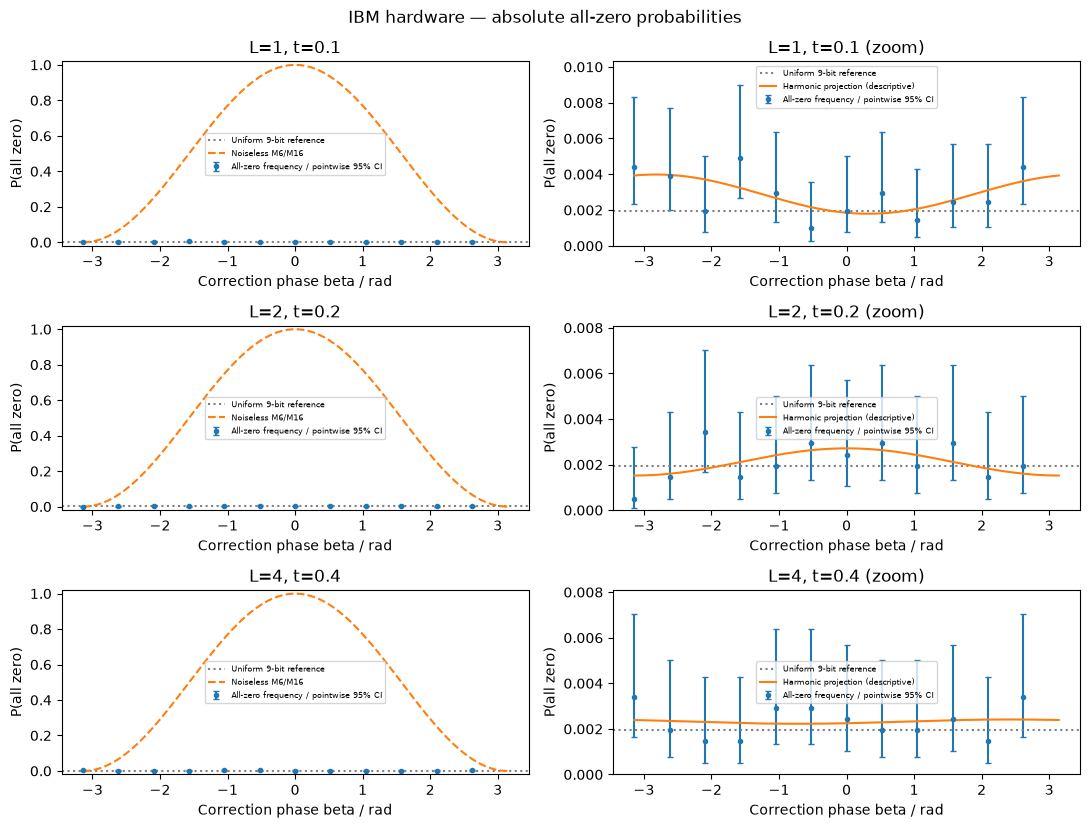

Saved analysis: outputs/exercise7/ibm_jobs/e9d6669ba09adf3a780824e1e52183ad8459eb36e3e1c6baeaa923f83506ce5e.analysis.json


In [9]:
def aggregate_hardware(record):
    spec = record["specification"]
    config = spec["configuration"]
    if config["circuit_digest"] != CIRCUIT_DIGEST:
        raise ValueError("保存countsと現在の準備・発展回路が異なります")
    if record.get("source") != "ibm_raw_counts":
        raise ValueError("実機の生countsがあるJSONを指定してください")
    phases = np.asarray(config["phases"], float)
    schedule, raw = spec["schedule"], record["counts"]
    validate_counts(raw, len(schedule))
    expected = {
        (r, length, j)
        for r in range(config["repeats"])
        for length in config["L_values"]
        for j in range(len(phases))
    }
    seen = set()
    totals = {
        length: [np.zeros(len(phases), dtype=int), np.zeros(len(phases), dtype=int)]
        for length in config["L_values"]
    }
    for row, counts in zip(schedule, raw):
        key = (row["repeat"], row["L"], row["phase_index"])
        if (
            key not in expected
            or key in seen
            or not np.isclose(row["beta"], phases[key[2]], atol=1e-12)
        ):
            raise ValueError("測定順序の欠損・重複・位相不一致があります")
        seen.add(key)
        k, n = totals[row["L"]]
        k[row["phase_index"]] += counts.get("0" * 9, 0)
        n[row["phase_index"]] += sum(counts.values())
    if seen != expected:
        raise ValueError("測定が完了していません")
    return [
        dict(L=length, **summarize_scan(phases, *totals[length], seed=42 + length))
        for length in config["L_values"]
    ]


RESULT_FILE = None  # 例: 'outputs/exercise7/ibm_jobs/<key>.json'
analysis_record = (
    json.loads(Path(RESULT_FILE).read_text()) if RESULT_FILE else hardware_record
)
analysis_path = Path(RESULT_FILE) if RESULT_FILE else hardware_path
if analysis_record is not None:
    hardware_scans = aggregate_hardware(analysis_record)
    print(
        "Backend:",
        analysis_record["specification"]["backend"],
        "job ID:",
        analysis_record["job_id"],
    )
    print_scan_summary(hardware_scans)
    plot_scans(hardware_scans, "IBM hardware — absolute all-zero probabilities")
    summary = dict(
        source="hardware_phase_diagnostic",
        job_id=analysis_record["job_id"],
        raw_counts_file=str(analysis_path),
        specification=analysis_record["specification"],
        scans=hardware_scans,
    )
    summary_path = analysis_path.with_suffix(".analysis.json")
    atomic_json(summary_path, summary)
    print("Saved analysis:", summary_path)
else:
    print(
        "実機countsなし。シミュレーション対照だけを表示しました。保存JSONの再解析もできます。"
    )


## 8．結果の読み方

- **L=1では明瞭、L=4では弱い：** 回路を長くすると干渉が失われる説明を支持します。
  理想信号・区間・実ゲート数と併せて比較し、必要ならRUN_LABELを変えた独立測定で再現性を確認します。
- **全Lで未検出：** Lに依存しない準備／逆準備の負荷、読出し、既にL=1で深すぎる回路も候補です。
  この比較だけでは原因を特定できません。shots不足で弱い信号を検出できない可能性もあります。
- **全Lで明瞭：** 06との違いには実行日時・較正・配置・位相範囲もあります。Lだけが原因とは結論できません。
- **1/512付近：** 一様な9ビット測定と同程度の全0頻度です。全ビット分布を調べずに完全脱分極と断定しません。

初期配置を揃えてもrouting・最終配置・実ゲート数はL間で変わり得ます。単一ジョブは較正を固定する保証ではありません。
この演習ではノイズ機構の分離、MPOとTrotterの直接比較、ノイズ下でのギャップ推定は行いません。

参考： [Kanno et al., PNAS (2025), Fig. 2](https://doi.org/10.1073/pnas.2425026122)、
[SamplerV2 v0.43](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/0.43/sampler-v2)、
[transpile v2.4](https://quantum.cloud.ibm.com/docs/en/api/qiskit/2.4/compiler)、
[NumPyの多変量超幾何分布](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.multivariate_hypergeometric.html)。
